In [1]:
import pandas as pd
import numpy as np
from scipy.stats import multivariate_normal
from scipy.stats import norm
import matplotlib.pyplot as plt
from statistics import mean, stdev

In [2]:
import os
from urllib.request import urlretrieve

def findfile(fname):
    if not os.path.isfile(fname):
        print(f'Downloading {fname}...')
        urlretrieve('https://github.com/TUDelft-MUDE/source-files/raw/main/file/'+fname, fname)

findfile('CPT_data.csv')

Number of paired observations: 743
Depth range: 0.10–14.92 m
[[ 1.37   0.037]
 [ 1.685  0.041]
 [ 1.96   0.045]
 ...
 [17.704  0.129]
 [17.266  0.131]
 [16.427  0.131]]


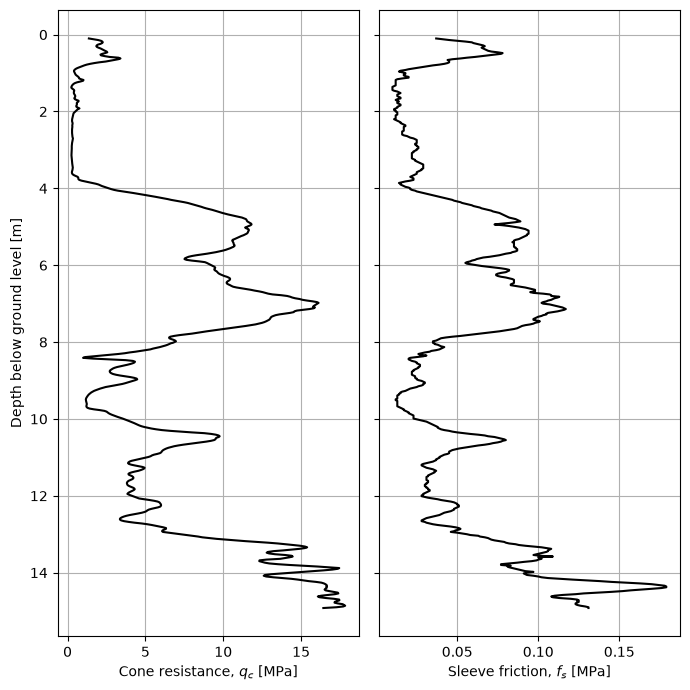

In [3]:
dataframe = pd.read_csv('CPT_data.csv')

# Only the variables required for this workshop
cpt = dataframe[['depth_m', 'qc_MPa', 'fs_MPa']].dropna()

# Inspect the real CPT profile
fig, axes = plt.subplots(1, 2, figsize=(7,7), sharey=True)
axes[0].plot(cpt['qc_MPa'], cpt['depth_m'], 'k')
axes[0].set_xlabel(r'Cone resistance, $q_c$ [MPa]')
axes[0].set_ylabel('Depth below ground level [m]')
axes[0].grid()

axes[1].plot(cpt['fs_MPa'], cpt['depth_m'], 'k')
axes[1].set_xlabel(r'Sleeve friction, $f_s$ [MPa]')
axes[1].grid()

axes[0].invert_yaxis()
plt.tight_layout()

# Use the complete set of paired qc-fs measurements
data = cpt[['qc_MPa', 'fs_MPa']].to_numpy()

print('Number of paired observations:', len(data))
print('Depth range: {:.2f}–{:.2f} m'.format(cpt.depth_m.min(), cpt.depth_m.max()))
print(data)

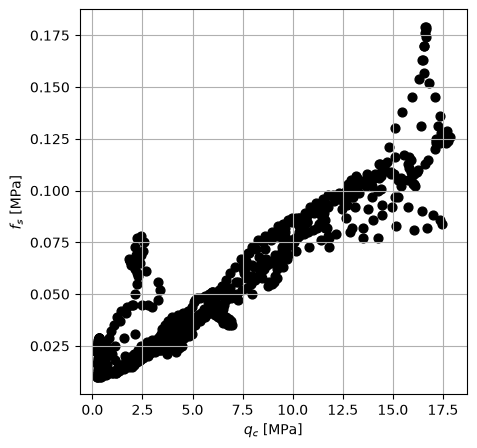

In [4]:
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(data[:,0], data[:,1], 40, 'k')
ax.set_ylabel(r'$f_s$ [MPa]')
ax.set_xlabel(r'$q_c$ [MPa]')
ax.grid()

In [5]:
def calculate_covariance(X1, X2):
    mean_x1 = mean(X1)
    mean_x2 = mean(X2)
    diff_x1 = X1-mean_x1
    diff_x2 = X2-mean_x2
    product = diff_x1*diff_x2
    covariance = sum(product) / (len(X1) - 1)
    return covariance

# Apply the function to the CPT data
covariance_qc_fs = calculate_covariance(data[:,0], data[:,1])

print('The covariance between qc and fs is',
      np.round(covariance_qc_fs, 5), 'MPa²')

The covariance between qc and fs is 0.17502 MPa²


In [6]:
def pearson_correlation(X1, X2):
    covariance = calculate_covariance(X1, X2)
    std_x1 = stdev(X1)
    std_x2 = stdev(X2)
    correl_coeff = covariance / (std_x1 * std_x2)
    return correl_coeff

# Apply the function to the CPT data
correlation_qc_fs = pearson_correlation(data[:,0], data[:,1])

print("Pearson's correlation coefficient between qc and fs is",
      np.round(correlation_qc_fs, 2))

Pearson's correlation coefficient between qc and fs is 0.93


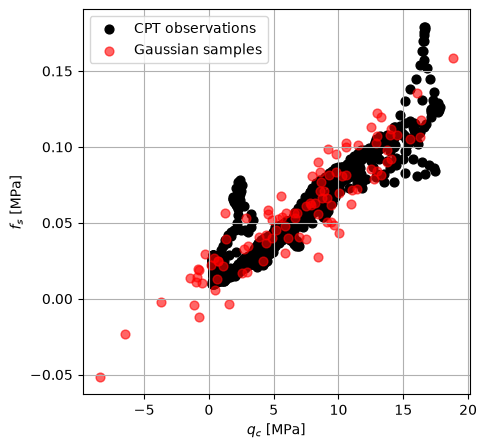

In [7]:
# Construct the mean vector
mu1 = mean(data[:,0])  # mean of qc
mu2 = mean(data[:,1])  # mean of fs
mu = np.array([mu1, mu2])

# Construct the covariance matrix
s1 = stdev(data[:,0])  # standard deviation of qc
s2 = stdev(data[:,1])  # standard deviation of fs

covariance_12 = calculate_covariance(data[:,0], data[:,1])

sigma = np.array([
    [s1**2, covariance_12],
    [covariance_12, s2**2]
])

# Draw 100 samples from the fitted bivariate Gaussian distribution
samples = multivariate_normal(mean=mu, cov=sigma).rvs(size=100)

# Compare samples with observations
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(data[:,0], data[:,1], 40, 'k', label='CPT observations')
ax.scatter(samples[:,0], samples[:,1], 40, 'r', alpha=0.6,
           label='Gaussian samples')
ax.set_ylabel(r'$f_s$ [MPa]')
ax.set_xlabel(r'$q_c$ [MPa]')
ax.grid()
ax.legend()

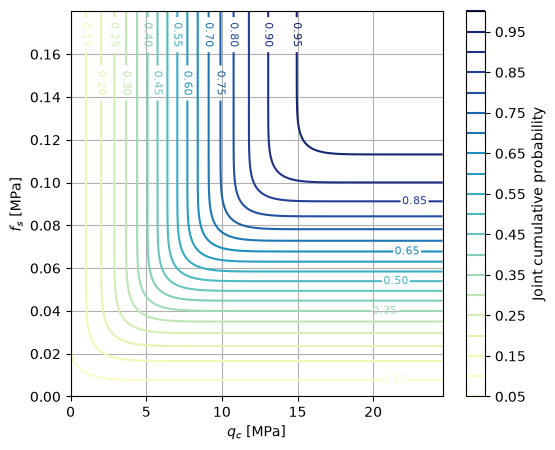

In [8]:
# Define a mesh over the range of interest
n = 200
values_qc = np.linspace(max(0, mu[0]-3.5*s1), mu[0]+3.5*s1, n)
values_fs = np.linspace(max(0, mu[1]-3.5*s2), mu[1]+3.5*s2, n)

# Define the grid
X1, X2 = np.meshgrid(values_qc, values_fs)

# Convert the 2D grids into 1D arrays
X1_1d = np.concatenate(X1.T)
X2_1d = np.concatenate(X2.T)

# Combine them so each row is one (qc, fs) point
X = np.array([X1_1d, X2_1d]).T

# Evaluate the bivariate CDF
Z = multivariate_normal(mean=mu, cov=sigma).cdf(X)

# Reshape the CDF values back to the mesh shape
Z = Z.reshape(X1.shape).T

# Plot CDF contours
fig, ax = plt.subplots(figsize=(6,5))

contours = ax.contour(
    X1, X2, Z,
    20,
    cmap='YlGnBu'
)

ax.clabel(contours, inline=True, fontsize=8)
ax.grid()

ax.set_xlabel(r'$q_c$ [MPa]')
ax.set_ylabel(r'$f_s$ [MPa]')

fig.colorbar(
    contours,
    ax=ax,
    label='Joint cumulative probability'
)

In [9]:
qc_high = 10.53250000
qc_threshold = 4.93950000
fs_threshold = 0.04200000

prob_qc_higher = 1 - norm.cdf(qc_high, loc=mu1, scale=s1)
print('P[qc > high threshold] =', np.round(prob_qc_higher, 3))

prob_joint_lower = multivariate_normal(mean=mu, cov=sigma).cdf([qc_threshold, fs_threshold])
print('P[qc <= threshold AND fs <= threshold] =', np.round(prob_joint_lower, 3))

prob_qc_lower = norm.cdf(qc_threshold, loc=mu1, scale=s1)
prob_fs_lower = norm.cdf(fs_threshold, loc=mu2, scale=s2)
prob_or_lower = prob_qc_lower + prob_fs_lower - prob_joint_lower
print('P[qc <= threshold OR fs <= threshold] =', np.round(prob_or_lower, 3))

prob_joint_upper = 1 - prob_qc_lower - prob_fs_lower + prob_joint_lower
print('P[qc > threshold AND fs > threshold] =', np.round(prob_joint_upper, 3))

prob_independent = (1-prob_qc_lower)*(1-prob_fs_lower)
print('If independence were assumed =', np.round(prob_independent, 3))

P[qc > high threshold] = 0.213
P[qc <= threshold AND fs <= threshold] = 0.324
P[qc <= threshold OR fs <= threshold] = 0.436
P[qc > threshold AND fs > threshold] = 0.564
If independence were assumed = 0.384


In [10]:
qc_observed = 4.93950000

cond_mu_fs = mu[1] + sigma[1,0] * sigma[0,0]**(-1) * (qc_observed - mu[0])
cond_var_fs = sigma[1,1] - sigma[1,0] * sigma[0,0]**(-1) * sigma[0,1]

print('Observed qc            =', np.round(qc_observed, 3), 'MPa')
print('Unconditional mean fs =', np.round(mu[1], 4), 'MPa')
print('Conditional mean fs   =', np.round(cond_mu_fs, 4), 'MPa')
print('Unconditional SD fs   =', np.round(np.sqrt(sigma[1,1]), 4), 'MPa')
print('Conditional SD fs     =', np.round(np.sqrt(cond_var_fs), 4), 'MPa')

Observed qc            = 4.94 MPa
Unconditional mean fs = 0.0539 MPa
Conditional mean fs   = 0.0444 MPa
Unconditional SD fs   = 0.036 MPa
Conditional SD fs     = 0.0128 MPa


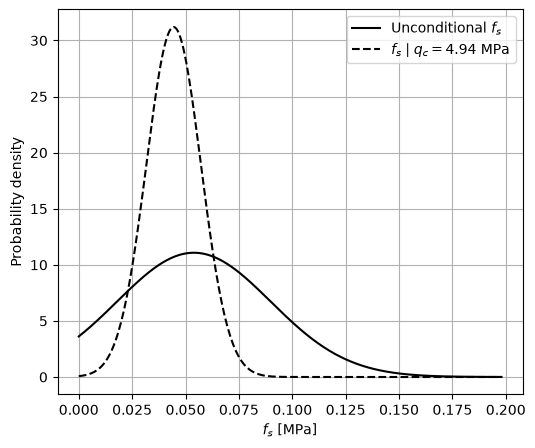

In [11]:
# Evaluate unconditional and conditional PDFs of fs
fs_plot = np.linspace(max(0, mu[1]-4*s2), mu[1]+4*s2, 300)

uncond_fs_pdf = norm.pdf(fs_plot, loc=mu[1], scale=np.sqrt(sigma[1,1]))
cond_fs_pdf = norm.pdf(fs_plot, loc=cond_mu_fs, scale=np.sqrt(cond_var_fs))

# Plot
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(fs_plot, uncond_fs_pdf, 'k', label='Unconditional $f_s$')
ax.plot(fs_plot, cond_fs_pdf, '--k',
        label=rf'$f_s \mid q_c={qc_observed:.2f}$ MPa')
ax.grid()
ax.set_xlabel(r'$f_s$ [MPa]')
ax.set_ylabel('Probability density')
ax.legend()